In [12]:
import numpy as np
import importlib 
import matplotlib.pyplot as plt

## Default setup for my figures ==================

plt.rcParams.update({'font.size': 9})
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
cm2in = 1/2.54
fig_format = '.pdf'
myColors = ['#626262', '#184e77', '#1A759F', '#34A0A4', '#76C893', '#B5E48C', '#EBF297']

# Import the Lifting-line solver libs ============

#import Solvers and functions:
import Lib.Classes
import Lib.MAIN
import Lib.Postprocessing
import Lib.Subsolvers

## Reload files:
importlib.reload(Lib.Classes);
importlib.reload(Lib.MAIN);
importlib.reload(Lib.Postprocessing);
importlib.reload(Lib.Subsolvers);

## These are the list of functions for this project. They are here only for reference.

#from Lib.Classes       import bladePanel
#from Lib.Classes       import wakeVortex

#from Lib.MAIN       import solveLinearSystem
from Lib.MAIN        import solveVortexPanels

from Lib.Postprocessing import showSystem
from Lib.Postprocessing import plotFields
from Lib.Postprocessing import makeGif
from Lib.Postprocessing import makeAnimation

from  Lib.Subsolvers import constructBladePanels
#from Lib.Subsolvers import inducedVelocity
#from Lib.Subsolvers import initializeInductionMatrix
#from Lib.Subsolvers import updateInductionMatrix
#from Lib.Subsolvers import moveBlade
#from Lib.Subsolvers import wakeInducedVelocity
from  Lib.Subsolvers import LEmotion

from Lib.Subsolvers import logGamma
#from Lib.Subsolvers import vortexRollUp

## 1. Increasing wake length ##

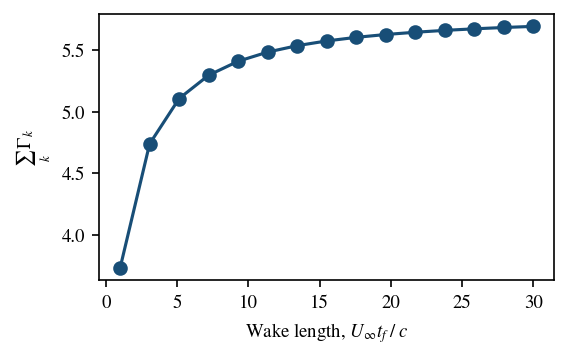

In [2]:
ncases = 15

alpha0       = 10 * np.pi/180 ## initial angle of attacks, rad
npanels      = 5              ## number of blade panels
finalTime    = np.linspace(0.1, 3, num=ncases)  ## total time of simulation, s
xVelocity    = -10            ## x-velocity of the airfoil, m/s
yVelocity    = 0.0            ## plunging velocity of the airfoil, m/s
rotFreq      = 0.0            ## rot. speed of the airfoil edge, Hz
rotAmplitude = 0.0            ## amplitude of rotational motion, m
plungAmpl    = 0.0            ## plunging amplitude, m
plungFreq    = 0.0            ## plunging frequency, Hz
nTimeSteps   = abs(10*xVelocity*finalTime).astype(int)  ## number of time steps

## Total circulation around the airfoil:
totalCirculation = np.zeros(len(finalTime))

for n in range(ncases):
      ## Below, we contruct and show the components of the panel system:
      myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0, npanels, nTimeSteps[n]) # construct the blade panels

      ## Here, we define the motion of the LE of the airfoil:
      Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps[n], finalTime[n], xVelocity, yVelocity, rotFreq, rotAmplitude, alpha0, plungAmpl, plungFreq)

      ## Updates circulation of myBladePanels, myTEVortex, myWakeVortexes
      ## returns: total circulation over airfoil at all time-steps
      solution = solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes, saveToFile=False)

      totalCirculation[n] = solution[-1]


## Plot results # =============================

fig, ax = plt.subplots(figsize=(11*cm2in, 6*cm2in), dpi=150)

plt.subplots_adjust(left=0.15, bottom=0.2, right=0.85, top=0.95)

ax.plot(abs( xVelocity*finalTime ), totalCirculation,'o-', color=myColors[1])
ax.set_xlabel(r'Wake length, $U_\infty t_f \; / \;c$');
ax.set_ylabel(r'$\sum_k \; \Gamma_k$');
plt.savefig("./Plots/WakeLength.pdf", dpi=300)

## 2. Increasing number of blade panels ##

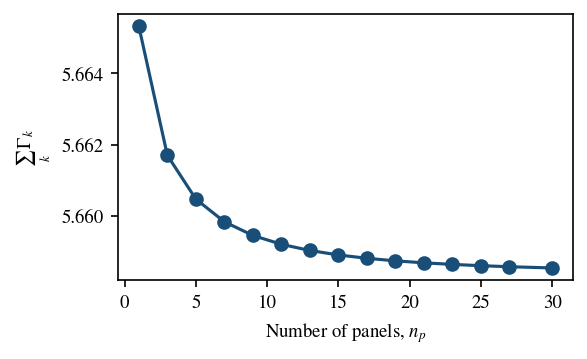

In [34]:
ncases = 15

alpha0       = 10 * np.pi/180  ## initial angle of attacks, rad
npanels      = np.linspace(1, 30, num=ncases, dtype=int) ## number of blade panels
finalTime    = 2.5           ## total time of simulation, s
xVelocity    = -10            ## x-velocity of the airfoil, m/s
yVelocity    = 0.0            ## plunging velocity of the airfoil, m/s
rotFreq      = 0.0            ## rot. speed of the airfoil edge, Hz
rotAmplitude = 0.0            ## amplitude of rotational motion, m
plungAmpl    = 0.0            ## plunging amplitude, m
plungFreq    = 0.0            ## plunging frequency, Hz
nTimeSteps   = int(abs(10*xVelocity*finalTime))  ## number of time steps

## Total circulation around the airfoil:
totalCirculation = np.zeros(len(npanels))

for n in range(ncases):
      ## Below, we contruct and show the components of the panel system:
      myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0, npanels[n], nTimeSteps)

      ## Here, we define the motion of the LE of the airfoil:
      Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps, finalTime, xVelocity, yVelocity, rotFreq, rotAmplitude, alpha0, plungAmpl, plungFreq)

      ## Updates circulation of myBladePanels, myTEVortex, myWakeVortexes
      ## returns: total circulation over airfoil at all time-steps
      solution = solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes, saveToFile=False)

      totalCirculation[n] = solution[-1]



## Plot results # =============================

fig, ax = plt.subplots(figsize=(11*cm2in, 6*cm2in), dpi=150)

plt.subplots_adjust(left=0.15, bottom=0.2, right=0.85, top=0.95)

ax.plot(npanels, totalCirculation, 'o-', color=myColors[1])
ax.set_xlabel(r'Number of panels, $n_p$');
ax.set_ylabel(r'$\sum_k \; \Gamma_k$');
plt.savefig("./Plots/NumberOfPanels.pdf", dpi=300)

## 3. Time-step sizing ##

* Notice that this metric is only important for the unsteady cases. Thus, we need to have at least one time of motion.

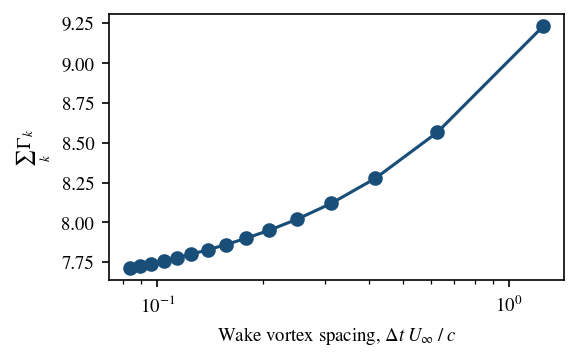

In [35]:
ncases = 15

alpha0       = 10 * np.pi/180  ## initial angle of attacks, rad
npanels      = 10             ## number of blade panels
finalTime    = 2.5            ## total time of simulation, s
xVelocity    = -10            ## x-velocity of the airfoil, m/s
yVelocity    = 0.0            ## plunging velocity of the airfoil, m/s
rotFreq      = 0.0            ## rot. speed of the airfoil edge, Hz
rotAmplitude = 0.0            ## amplitude of rotational motion, m
plungAmpl    = 0.3            ## plunging amplitude, m
plungFreq    = 1.0            ## plunging frequency, Hz
nTimeSteps   = np.linspace(20, 300, num=ncases, dtype=int)*int(plungFreq) ## number of time steps

## Total circulation around the airfoil:
totalCirculation = np.zeros(len(nTimeSteps))

for n in range(ncases):

      ## Below, we contruct and show the components of the panel system:
      myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0, npanels, nTimeSteps[n]) # construct the blade panels

      ## Here, we define the motion of the LE of the airfoil:
      Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps[n], finalTime, xVelocity, yVelocity, rotFreq, rotAmplitude, alpha0, plungAmpl, plungFreq)

      ## Updates circulation of myBladePanels, myTEVortex, myWakeVortexes
      ## returns: total circulation over airfoil at all time-steps
      solution = solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes, saveToFile=False)

      totalCirculation[n] = solution[-1]


## Plot results ##

fig, ax = plt.subplots(figsize=(11*cm2in, 6*cm2in), dpi=150)

plt.subplots_adjust(left=0.15, bottom=0.2, right=0.85, top=0.95)

vortex_spacing = (finalTime*-xVelocity/nTimeSteps)

ax.semilogx(vortex_spacing, totalCirculation, 'o-', color=myColors[1])
ax.set_xlabel(r'Wake vortex spacing, $\Delta t \; U_\infty \;/\; c$');
ax.set_ylabel(r'$\sum_k \; \Gamma_k$');
plt.savefig("./Plots/TimeStepSizing.pdf", dpi=300)

## 4. Steady-state solution ##

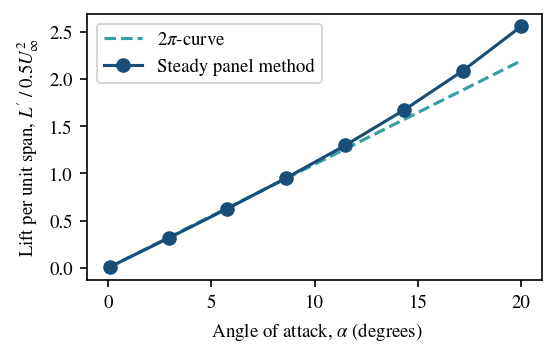

In [36]:
ncases = 8

alpha0       = np.linspace(0.1, 20, num=ncases) * np.pi/180  ## initial angle of attacks, rad
npanels      = 10             ## number of blade panels
finalTime    = 2.5            ## total time of simulation, s
xVelocity    = -10            ## x-velocity of the airfoil, m/s
yVelocity    = 0.0            ## plunging velocity of the airfoil, m/s
rotFreq      = 0.0            ## rot. speed of the airfoil edge, Hz
rotAmplitude = 0.0            ## amplitude of rotational motion, m
plungAmpl    = 0.0            ## plunging amplitude, m
plungFreq    = 0.0            ## plunging frequency, Hz
nTimeSteps   = 10 * int( abs(finalTime*xVelocity) ) ## number of time steps 10, for steady cases


## Total circulation around the airfoil:
totalCirculation = np.zeros(len(alpha0))

for n in range(ncases):

      ## Below, we contruct and show the components of the panel system:
      myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0[n], npanels, nTimeSteps) # construct the blade panels

      myWakeVortexes = np.empty(nTimeSteps-1, dtype=object) # constructWakeVortexes(nTimeSteps)

      ## Here, we define the motion of the LE of the airfoil:
      Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps, finalTime, xVelocity, yVelocity, rotFreq, rotAmplitude, alpha0[n], plungAmpl, plungFreq)

      ## Updates circulation of myBladePanels, myTEVortex, myWakeVortexes
      ## returns: total circulation over airfoil at all time-steps
      solution = solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes, saveToFile=False)

      totalCirculation[n] = solution[-1]


## Plot results # =============================

CL        = totalCirculation * np.cos(alpha0) / (0.5 * -U[-1]) # lift coeff.
alphaTheo = [0, 20]
clTheo    = [np.sin(0), 2*np.pi*np.deg2rad(20) ]



fig, ax = plt.subplots(figsize=(11*cm2in, 6*cm2in), dpi=150)

plt.subplots_adjust(left=0.15, bottom=0.2, right=0.85, top=0.95)

ax.plot(alphaTheo, clTheo, '--', color=myColors[3], label=r'$2\pi$-curve')
ax.plot(np.rad2deg(alpha0), CL, 'o-', color=myColors[1], label='Steady panel method')
ax.set_xlabel(r' Angle of attack, $\alpha$ (degrees)');
ax.set_ylabel(r'Lift per unit span, $L^\prime \; / \; 0.5 U_{\infty}^2$');
ax.legend()
plt.savefig("./Plots/SteadyCases.pdf", dpi=300)

## 5. Plunging case ##

Vortex spacing: 0.786


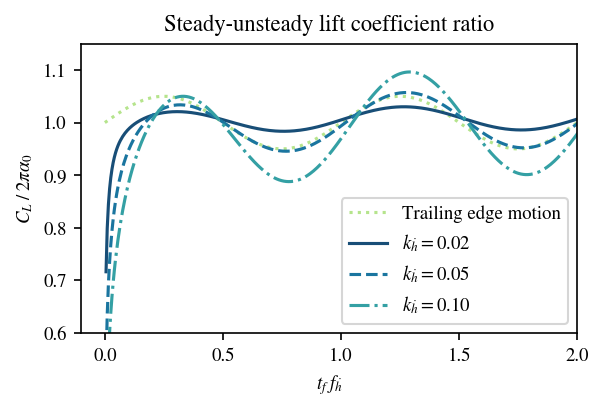

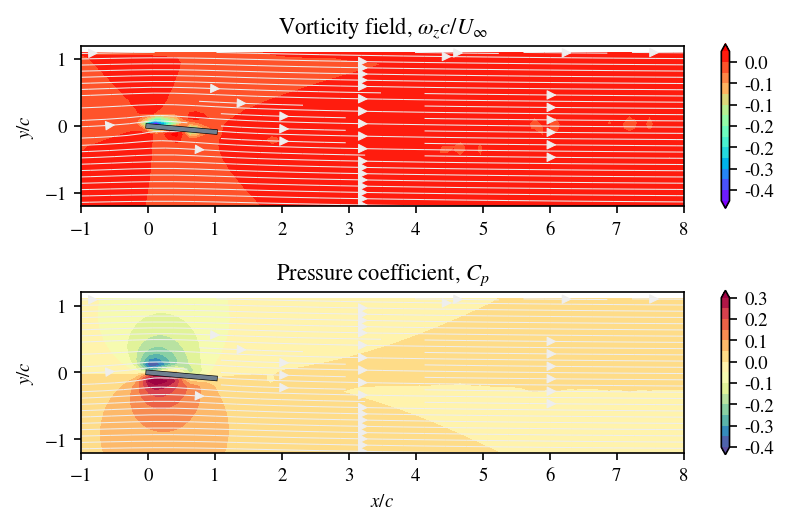

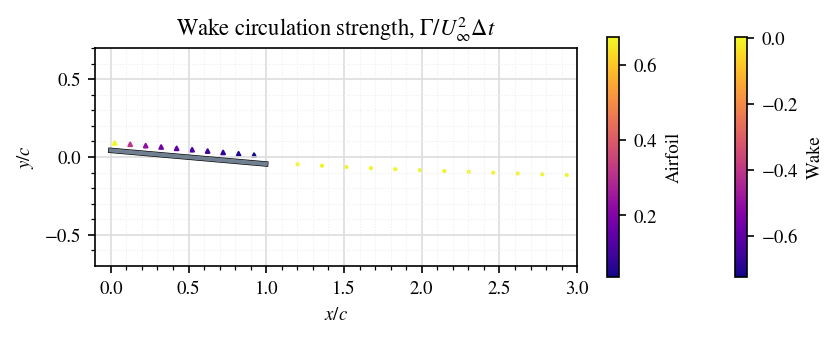

In [5]:
ncases = 3
k = np.array([0.02, 0.05, 0.1]) ## Reduced frequencies: k = omega*chord/(2*U) 


alpha0       = 5 * np.pi/180  ## initial angle of attacks, rad
npanels      = 10              ## number of blade panels
xVelocity    = -10             ## x-velocity of the airfoil, m/s
yVelocity    = 0.0             ## plunging velocity of the airfoil, m/s
rotFreq      = 0.0             ## rot. speed of the airfoil edge, Hz
rotAmplitude = 0.0             ## amplitude of rotational motion, m
plungAmpl    = 0.05            ## plunging amplitude, m
plungFreq    = k * np.abs(xVelocity) / np.pi ## plunging frequency, Hz
finalTime    = (2.3/plungFreq).astype(int)        ## total time of simulation, s
nTimeSteps   = (200*finalTime*plungFreq).astype(int) ## number of time steps


print('Vortex spacing: %0.3f' % (finalTime[0]*-xVelocity/nTimeSteps[0]) )


fig, ax = plt.subplots(1, figsize=(12*cm2in, 7*cm2in), dpi=150)
plt.subplots_adjust(left=0.15, bottom=0.2, right=0.85, top=0.9)


THETA = np.linspace(0,2,num=100)
SINTHETA = 1 + 0.05*np.sin(plungFreq[2] * 2 * np.pi * THETA * np.pi) 
ax.plot( THETA,  SINTHETA, ':', color = myColors[5], label='Trailing edge motion')


lines = ['-','--','-.']

for n in range(ncases):

      ## Below, we contruct and show the components of the panel system:
      myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0, npanels, nTimeSteps[n]) # construct the blade panels

      ## Here, we define the motion of the LE of the airfoil:
      Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps[n], finalTime[n], xVelocity, yVelocity, rotFreq, rotAmplitude, alpha0, plungAmpl, plungFreq[n])

      solution = solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes, saveToFile=False)

      Uinf = np.array( [-U[-1], -V[-1]] )

      ## Plot lift coefficient / 2 pi Alpha:
      CL = (solution * np.cos(Theta[1:]) * Uinf[0]) / (0.5 *  Uinf[0]**2)

      ax.plot(Time[1:] * plungFreq[n], CL / (2 * np.pi * alpha0), lines[n], color=myColors[n+1], label=r'$k_{\dot{h}}=$%0.2f' % (k[n]), markersize=2) 


## Plot results # =============================
ax.set_xlabel(r'$ t_f \; f_{\dot{h}}$');
ax.set_ylabel(r'$C_L \; / \; 2\pi \alpha_0$');
ax.set_xlim([-0.1,2])
ax.set_ylim([0.6,1.15])
ax.legend()
ax.set_title('Steady-unsteady lift coefficient ratio')
plt.savefig("./Plots/CL_PlungingMotion.pdf", dpi=300)


## Show also the (last) system at the final time-step
plotFields(myWakeVortexes, myBladePanels, myTEVortex,  Uinf)
plt.savefig("./Plots/PlungingSystem" + str(n) + ".pdf", dpi=300)


showSystem(myBladePanels, myTEVortex, myWakeVortexes, Uinf, timeStep[-1])

## 6. Pitching cases ##

Vortex spacing: 0.788


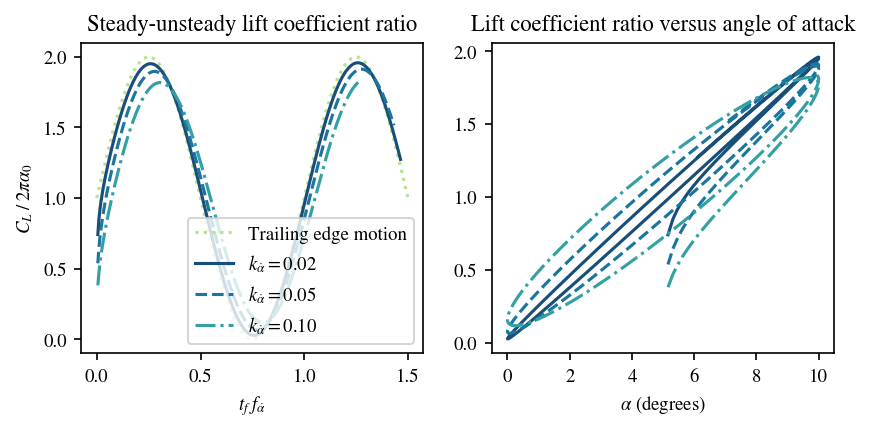

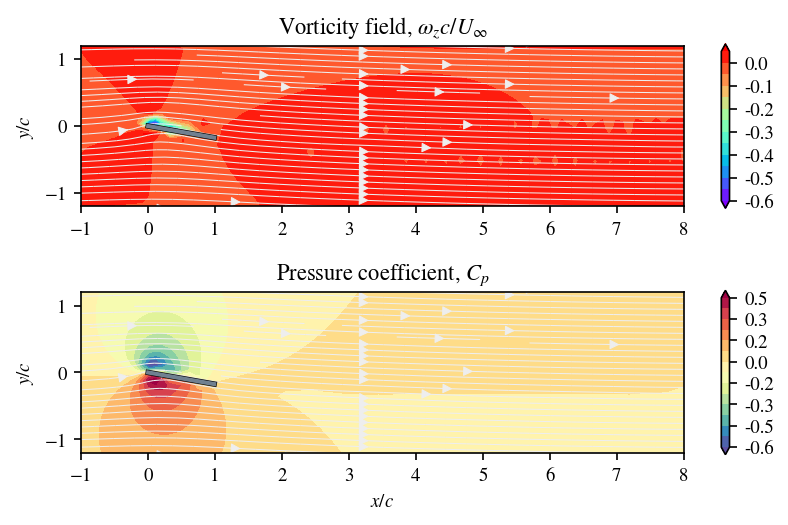

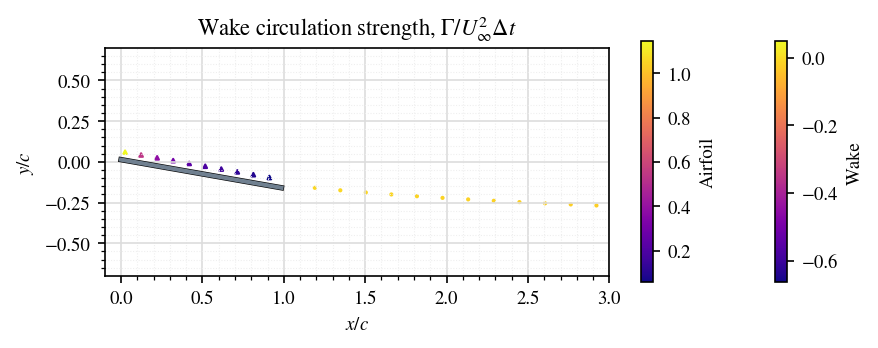

In [26]:
ncases = 3
k = np.array([0.02, 0.05, 0.1]) ## Reduced frequencies: k = omega*chord/(2*U) 


alpha0       = 5 * np.pi/180   ## initial angle of attacks, rad
npanels      = 10              ## number of blade panels
xVelocity    = -10             ## x-velocity of the airfoil, m/s
yVelocity    = 0.0             ## plunging velocity of the airfoil, m/s
rotFreq      = k * np.abs(xVelocity) / np.pi ## rot. speed of the airfoil edge, Hz
rotAmplitude = 5 * np.pi/180   ## amplitude of rotational motion, m
plungAmpl    = 0.0             ## plunging amplitude, m
plungFreq    = 0.0             ## plunging frequency, Hz
finalTime    = (1.5/rotFreq).astype(int)        ## total time of simulation, s
nTimeSteps   = (200*finalTime*rotFreq).astype(int) ## number of time steps
print('Vortex spacing: %0.3f' % (finalTime[0]*-xVelocity/nTimeSteps[0]) )



fig, axs = plt.subplots(1,2,figsize=(15*cm2in, 7*cm2in), dpi=150)
plt.subplots_adjust(left=0.1, bottom=0.15, right=0.95, top=0.9)
lines = ['-','--','-.']


THETA = np.linspace(0,1.5,num=100)
SINTHETA = 1 + np.sin(rotFreq[2] * 2 * np.pi * THETA * np.pi) 
axs[0].plot( THETA,  SINTHETA, ':', color = myColors[5], label='Trailing edge motion')


for n in range(ncases):

      ## Below, we contruct and show the components of the panel system:
      myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0, npanels, nTimeSteps[n]) # construct the blade panels

      ## Here, we define the motion of the LE of the airfoil:
      Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps[n], finalTime[n], xVelocity, yVelocity, rotFreq[n], rotAmplitude, alpha0, plungAmpl, plungFreq)

      solution = solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes, saveToFile=False)

      Uinf = np.array( [-U[-1], -V[-1]] )

      ## Plot lift coefficient / 2 pi Alpha:
      CL = (solution * np.cos(Theta[1:]) * Uinf[0]) / (0.5 *  Uinf[0]**2)

      axs[0].plot(Time[1:] * rotFreq[n], CL / (2 * np.pi * alpha0), lines[n], color=myColors[n+1], label=r'$k_{\dot{\alpha}}=$%0.2f' % (k[n])) 
      axs[1].plot(Theta[1:] * 180/np.pi, CL / (2 * np.pi * alpha0), lines[n], color=myColors[n+1]) 


## Plot results # =============================

axs[0].set_title('Steady-unsteady lift coefficient ratio')
axs[0].set_xlabel(r'$ t_f \; f_{\dot{\alpha}}$');
axs[0].set_ylabel(r'$C_L \; / \; 2\pi \alpha_0$');
axs[0].legend(loc='lower right')

axs[1].set_title('Lift coefficient ratio versus angle of attack')
axs[1].set_xlabel(r'$\alpha$ (degrees)');
plt.savefig("./Plots/CL_PitchingMotion.pdf", dpi=300)


## SHow also the system at the final time-step
plotFields(myWakeVortexes, myBladePanels, myTEVortex, Uinf)
plt.savefig("./Plots/PitchingSystem" + str(n) + ".pdf", dpi=300)


showSystem(myBladePanels, myTEVortex, myWakeVortexes, Uinf, timeStep[-1])

## 7. Steady flow

Vortex spacing: 0.010
Total Gamma (Blade): 0.20
Total Gamma (TE): -0.00
Total Gamma (Wake): -0.20
Total Gamma: -0.00



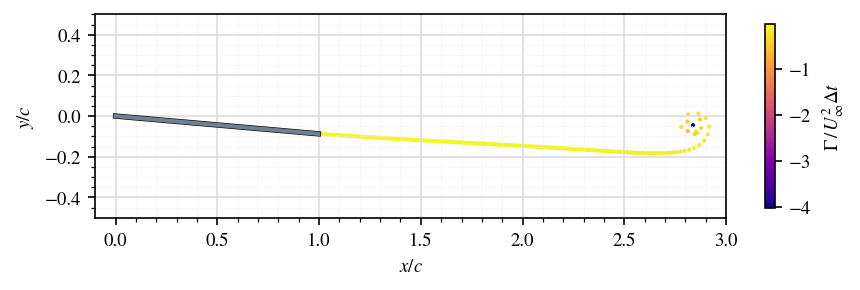

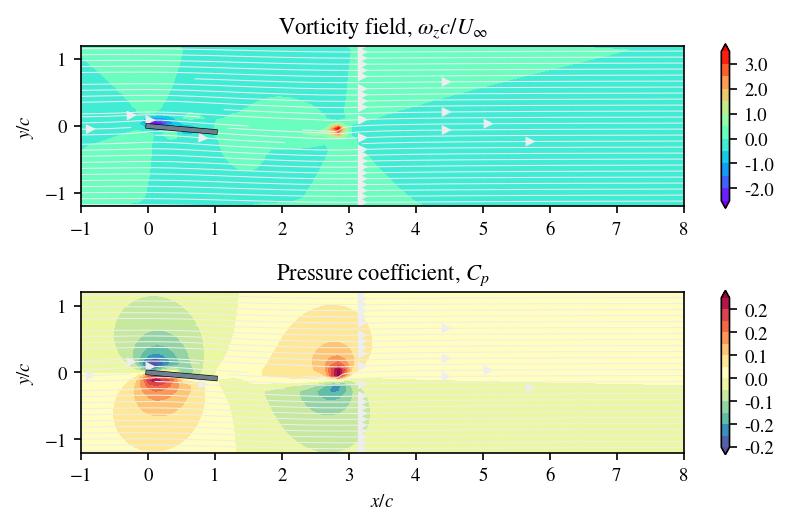

In [13]:
alpha0       = 5. * np.pi/180 ## initial angle of attacks, rad
npanels      = 10              ## number of blade panels
xVelocity    = -1             ## x-velocity of the airfoil, m/s
yVelocity    = 0.             ## plunging speed, m/s
rotFreq      = 0.             ## rot. speed of the airfoil, Hz
rotAmplitude = 0.             ## amplitude of rotational motion, m
plungAmpl    = 0.0            ## plunging amplitude, m
plungFreq    = 0.0            ## plunging frequency, Hz
finalTime    = 1.9*np.abs(1/xVelocity)     ## total sim. time, s
nTimeSteps   = int(1.9/0.01)   ## number of time steps

print('Vortex spacing: %0.3f' % (finalTime*-xVelocity/nTimeSteps) )

## Below, we contruct and show the components of the panel system:
myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0, npanels, nTimeSteps) # construct the blade panels


## Here, we define the motion of the LE of the airfoil:
Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps, finalTime, xVelocity, yVelocity, rotFreq, rotAmplitude, alpha0, plungAmpl, plungFreq)

Uinf = np.array( [-U[-1], -V[-1]] )

## Solve the system:
solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes)

showSystem(myBladePanels, myTEVortex, myWakeVortexes, Uinf, timeStep[-1])
plt.savefig("./Plots/SteadySystem_Particles.pdf", dpi=300)


## Plot the results ##
Uinf = np.array([-U[-1], -V[-1]]) ## define the reference velocity


plotFields(myWakeVortexes, myBladePanels, myTEVortex, Uinf)
plt.savefig("./Plots/SteadySystem_Fields.pdf", dpi=300)


## Make an animation of the vortex sheeding
makeAnimation(nTimeSteps)


## Determine total circulation over the airfoil, latest shed vortex and wake:
logGamma(myBladePanels, myTEVortex, myWakeVortexes)

## 8. Run a plunging case and make an animation

Reduced frequency: 8.50
Vortex spacing: 0.002

Total Gamma (Blade): 0.32
Total Gamma (TE): 0.01
Total Gamma (Wake): -0.32
Total Gamma: 0.01



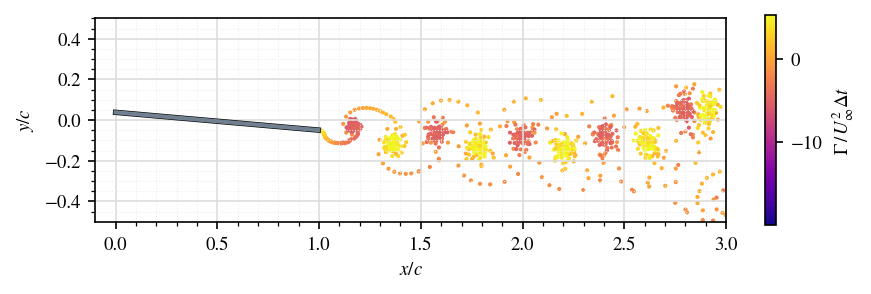

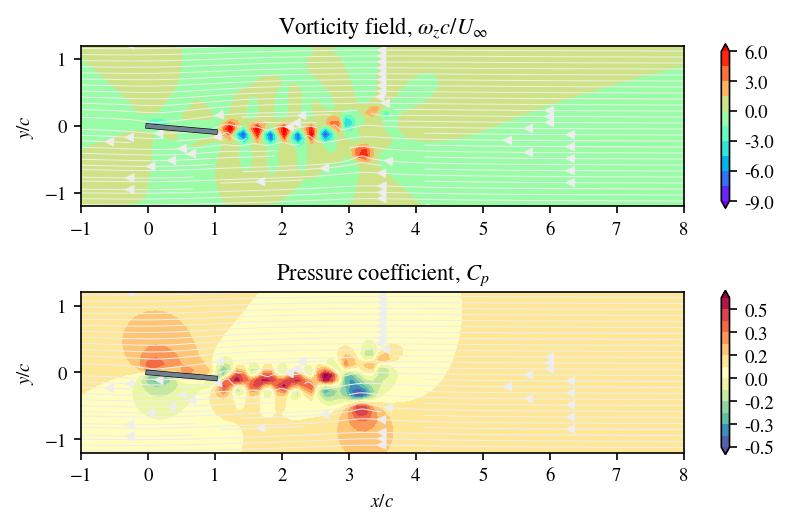

In [7]:
alpha0       = 5. * np.pi/180 ## initial angle of attacks, rad
npanels      = 10              ## number of blade panels
xVelocity    = -1             ## x-velocity of the airfoil, m/s
yVelocity    = 0.             ## plunging speed, m/s
rotFreq      = 0.             ## rot. speed of the airfoil, Hz
rotAmplitude = 0.             ## amplitude of rotational motion, m
plungAmpl    = 0.019          ## plunging amplitude, m
plungFreq    = 8.5/np.pi      ## plunging frequency, Hz
finalTime    = 2.4*np.abs(1/xVelocity)     ## total sim. time, s
nTimeSteps   = int(4/0.004)   ## number of time steps

k = 2*np.pi*plungFreq / (2*np.abs(xVelocity))

print('Reduced frequency: %0.2f' % (k) )
print('Vortex spacing: %0.3f\n' % (finalTime*-xVelocity/nTimeSteps) )

## Below, we contruct and show the components of the panel system:
myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0, npanels, nTimeSteps) # construct the blade panels


## Here, we define the motion of the LE of the airfoil:
Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps, finalTime, xVelocity, yVelocity, rotFreq, rotAmplitude, alpha0, plungAmpl, plungFreq)

## Solve the system:
solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes)

Uinf =  np.array([-max(-U), -max(V)]) # Normalize by maximum velocity

showSystem(myBladePanels, myTEVortex, myWakeVortexes, Uinf, timeStep[-1])
plt.savefig("./Plots/PlungingSystem_Particles.pdf", dpi=300)


plotFields(myWakeVortexes, myBladePanels, myTEVortex, Uinf)
plt.savefig("./Plots/PlungingSystem_Fields.pdf", dpi=300)


## Make an animation of the vortex sheeding
makeAnimation(nTimeSteps)

## Determine total circulation over the airfoil, latest shed vortex and wake:
logGamma(myBladePanels, myTEVortex, myWakeVortexes)

## 9. Pitching airfoil: make animation

Reduced frequency: 3.50
Vortex spacing: 0.007


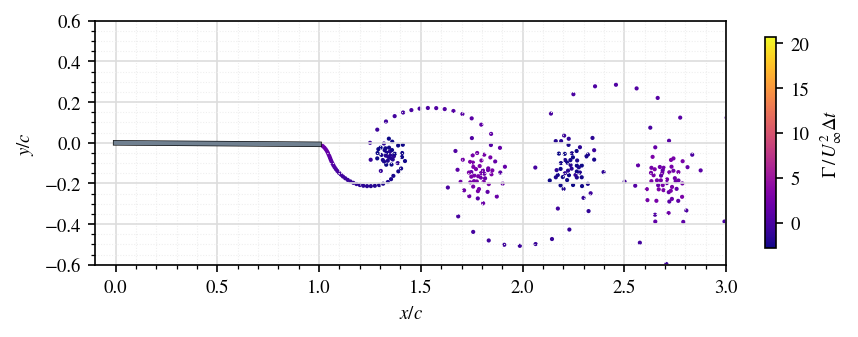

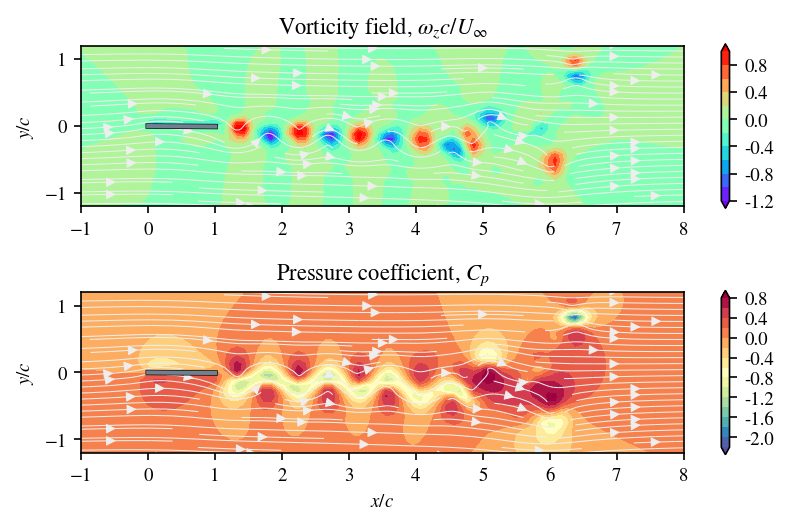

In [4]:
alpha0       = 5 * np.pi/180 ## initial angle of attacks, rad
npanels      = 10             ## number of blade panels
xVelocity    = -10            ## x-velocity of the airfoil, m/s
yVelocity    = 0.0            ## plunging velocity of the airfoil, m/s
rotFreq      = 35/np.pi       ## rot. speed of the airfoil edge, Hz
rotAmplitude = 5 * np.pi/180  ## amplitude of rotational motion, m
plungAmpl    = 0              ## plunging amplitude, m
plungFreq    = 0              ## plunging frequency, Hz
finalTime    = 6.0*np.abs(1/xVelocity)     ## total sim. time, s
nTimeSteps   = int(8.04/0.01)   ## number of time steps

k = 2*np.pi*rotFreq / (2*np.abs(xVelocity))

print('Reduced frequency: %0.2f' % (k) )
print('Vortex spacing: %0.3f' % (finalTime*-xVelocity/nTimeSteps) )

## Below, we contruct and show the components of the panel system:
myBladePanels, myTEVortex, myWakeVortexes  = constructBladePanels(alpha0, npanels, nTimeSteps) # construct the blade panels


## Here, we define the motion of the LE of the airfoil:
Time, timeStep, X, Y, U, V, Theta, Omega = LEmotion(nTimeSteps, finalTime, xVelocity, yVelocity, rotFreq, rotAmplitude, alpha0, plungAmpl, plungFreq)


## Solve the system:
solveVortexPanels(timeStep, U, V, myBladePanels, Theta, myTEVortex, myWakeVortexes, saveToFile=True)


## Plot the results ##
Uinf = np.array([-U[-1], -V[-1]]) ## define the reference velocity


showSystem(myBladePanels, myTEVortex, myWakeVortexes, Uinf, timeStep[-1])
plt.savefig("./Plots/PitchingSystem_Particles.pdf", dpi=300)


plotFields(myWakeVortexes, myBladePanels, myTEVortex, Uinf)
plt.savefig("./Plots/PitchingSystem_Fields.pdf", dpi=300)

## Make an animation of the vortex sheeding
makeAnimation(nTimeSteps)